<a href="https://colab.research.google.com/github/rahs2015/mat422/blob/main/MAT_422_%7C_HW_3_5_%26_3_6_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MAT 422 | HW 3.5 & 3.6 : K Means + SVM

In [10]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

from sklearn.datasets import make_moons

np.set_printoptions(precision=4, suppress=True)

# 3.5 K means
The inherent idea behind the K means is categorizes data into different spaces noted as clusters. These clusters are driven and divided through the assignment of a provided mean based on the closest point. This is seen below in the graph with the addition of clusters giving 2 different views of clusters. The inertia is the total squared distance between each point and its assigned center. The lower the inertia the more centrailzed the data is to the mean.

Results with 2 clusters
Cluster centers:
[[1.1583 3.175 ]
 [5.875  3.325 ]]
Inertia: 126.417

Results with 4 clusters
Cluster centers:
[[1.1167 1.1167]
 [5.8333 5.6833]
 [5.9167 0.9667]
 [1.2    5.2333]]
Inertia: 8.793


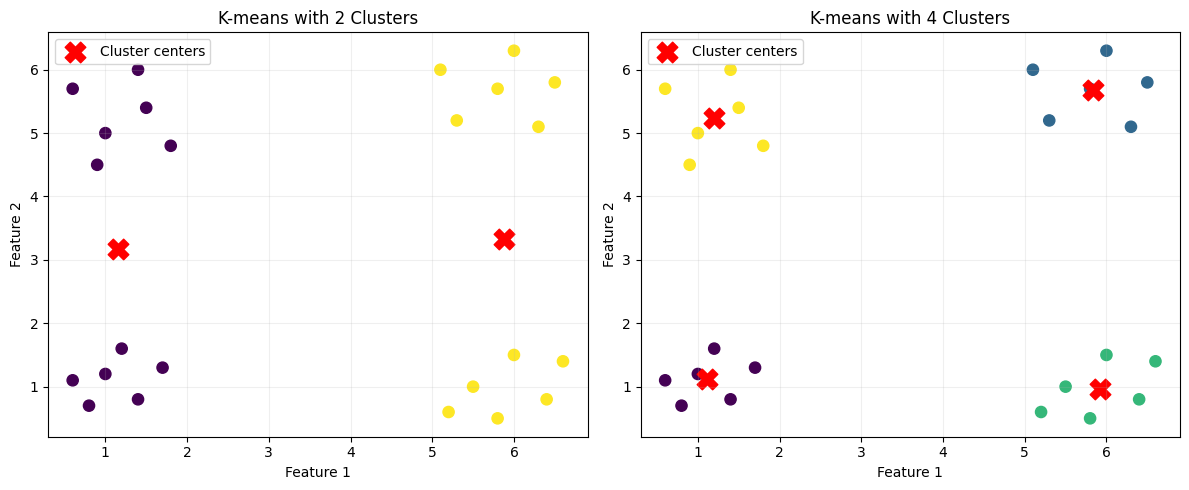

In [16]:
group1 = np.array([
    [1.0, 1.2], [1.4, 0.8], [0.8, 0.7],
    [1.2, 1.6], [1.7, 1.3], [0.6, 1.1]
])

group2 = np.array([
    [1.0, 5.0], [1.5, 5.4], [0.6, 5.7],
    [1.8, 4.8], [0.9, 4.5], [1.4, 6.0]
])

group3 = np.array([
    [5.5, 1.0], [6.0, 1.5], [6.4, 0.8],
    [5.2, 0.6], [6.6, 1.4], [5.8, 0.5]
])

group4 = np.array([
    [5.3, 5.2], [5.8, 5.7], [6.3, 5.1],
    [6.5, 5.8], [5.1, 6.0], [6.0, 6.3]
])



X = np.vstack((group1, group2, group3, group4))
model2 = KMeans(n_clusters=2, n_init=10, random_state=12)
model4 = KMeans(n_clusters=4, n_init=10, random_state=12)
labels2 = model2.fit_predict(X)
labels4 = model4.fit_predict(X)



print("Results with 2 clusters")
print("Cluster centers:")
print(model2.cluster_centers_)
print("Inertia:", round(model2.inertia_, 3))
print("\nResults with 4 clusters")
print("Cluster centers:")
print(model4.cluster_centers_)
print("Inertia:", round(model4.inertia_, 3))



fig, axes = plt.subplots(1, 2, figsize=(12, 5))



axes[0].scatter(
    X[:, 0], X[:, 1],
    c=labels2, cmap="viridis", s=65
)

axes[0].scatter(
    model2.cluster_centers_[:, 0],
    model2.cluster_centers_[:, 1],
    marker="X", s=220, color="red",
    label="Cluster centers"
)

axes[0].set_title("K-means with 2 Clusters")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].legend()
axes[0].grid(alpha=0.2)



axes[1].scatter(
    X[:, 0], X[:, 1],
    c=labels4, cmap="viridis", s=65
)

axes[1].scatter(
    model4.cluster_centers_[:, 0],
    model4.cluster_centers_[:, 1],
    marker="X", s=220, color="red",
    label="Cluster centers"
)

axes[1].set_title("K-means with 4 Clusters")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].legend()
axes[1].grid(alpha=0.2)


plt.tight_layout()
plt.show()

# 3.6 Support Vector Machines
Using different classes, support vector machines through a hyperplane that separates classes of data. The SVM is able to maximize the margin between its boundaries and its closest points. The graph below shows the prediction of each class using a curved boundary accomplished by RBF kernel due to the data's inability to be separated nicely using a straight line. The accuracy is based on the proportion of points classified correctly.

Accuracy: 0.987
Number of support vectors: 35


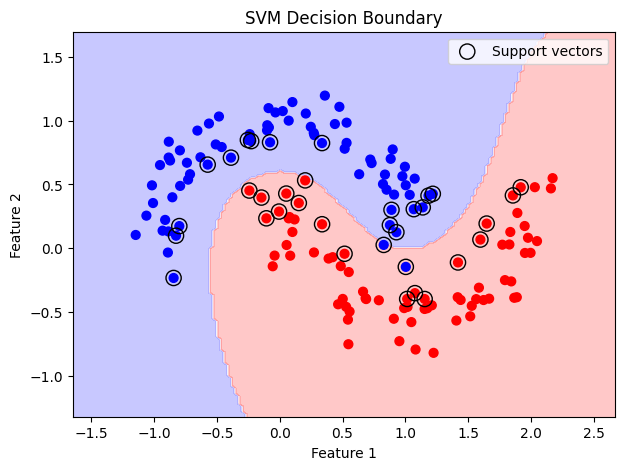

In [11]:
X, y = make_moons(n_samples=150, noise=0.15, random_state=10)

svm = SVC(kernel="rbf", C=1.0)
svm.fit(X, y)


predictions = svm.predict(X)
accuracy = accuracy_score(y, predictions)

print("Accuracy:", round(accuracy, 3))
print("Number of support vectors:", len(svm.support_vectors_))


xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 150),
    np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 150)
)



grid = np.c_[xx.ravel(), yy.ravel()]
Z = svm.predict(grid).reshape(xx.shape)
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="bwr")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", s=40)


plt.scatter(
    svm.support_vectors_[:, 0],
    svm.support_vectors_[:, 1],
    s=120, facecolors="none", edgecolors="black",
    label="Support vectors"
)


plt.title("SVM Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

* I explained my sections in words before my code.
* I double checked my core numerical claims
* I changed and/or extended at least one to make this homework my own.
* I ran this from to bottom without issues.
* I am saving this to github under my mat422 repository.